In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from scipy import integrate, interpolate, stats
import numericalunits as nu

import pandas as pd
from tqdm import tqdm

import wimprates

/opt/XENONnT/anaconda/envs/XENONnT_el7.sr01_solar_pp.2/lib/python3.9/site-packages/wimprates/__init__.py:6: UserWarning: Default WIMP parameters are changed in accordance with https://arxiv.org/abs/2105.00599 (github.com/JelleAalbers/wimprates/pull/14)
  warnings.warn(


In [2]:
perkevtonyear = ((1000 * nu.kg)**-1 * nu.year**-1 * nu.keV**-1)
# If you wnat to see low mass SI rate you need a small binning
es = np.arange(0, 60, 0.05)

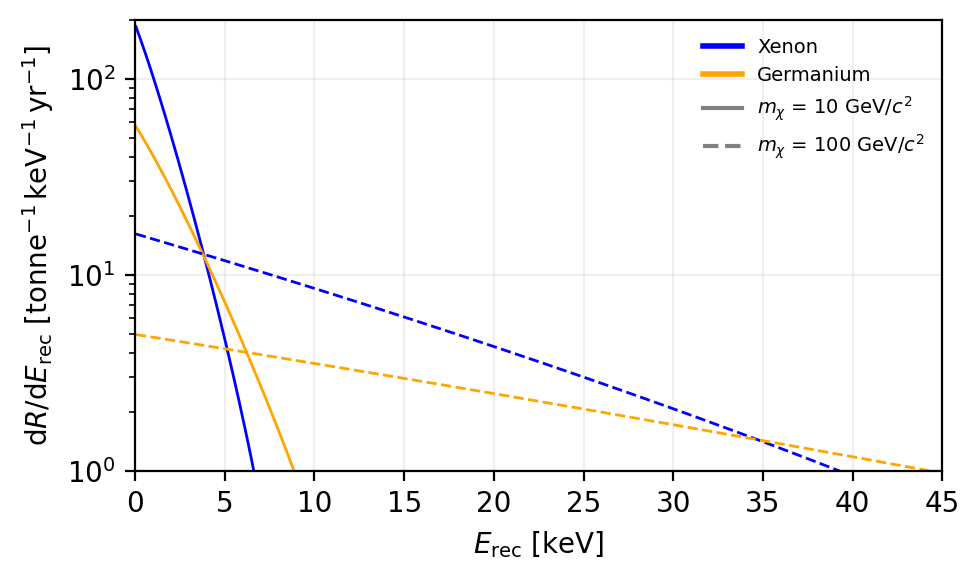

In [5]:
color_Xe = 'blue'
color_Ge = 'orange'
masses = [10, 100]
linestyles = ["-", "--", "-.", ":"]

plt.figure(figsize=(5, 3), dpi=200)

for (_m, _ls) in zip(masses, linestyles):
    # Removed the 'label' argument from these plots to avoid legend clutter
    plt.plot(es, 
             wimprates.rate_elastic(es * nu.keV, 
                                    mw = _m * nu.GeV/nu.c0**2, 
                                    sigma_nucleon = 1e-45 * nu.cm**2,
                                    interaction = 'SI', 
                                    material='Xe') / perkevtonyear,
             color=color_Xe, linewidth=1, ls=_ls)
    plt.plot(es, 
             wimprates.rate_elastic(es * nu.keV, 
                                    mw = _m * nu.GeV/nu.c0**2, 
                                    sigma_nucleon = 1e-45 * nu.cm**2,
                                    interaction = 'SI', 
                                    material='Ge') / perkevtonyear,
             color=color_Ge, linewidth=1, ls=_ls)

plt.xlabel(r'$E_{\mathrm{rec}}$ [keV]')
plt.ylabel(r"$\mathrm{d}R/\mathrm{d}E_{\mathrm{rec}}$ [$\mathrm{tonne}^{-1} \, \mathrm{keV}^{-1} \, \mathrm{yr}^{-1}$]")

plt.yscale('log')
plt.ylim(1e0, 2e2)
# plt.xscale('log')
# plt.xlim(1e-1, 50)
plt.xlim(0, 45)

plt.grid(alpha=0.2, linestyle='-')

# Handles for the materials (Colors)
handle_xe = Line2D([0], [0], color=color_Xe, lw=2, label='Xenon')
handle_ge = Line2D([0], [0], color=color_Ge, lw=2, label='Germanium')

# Handles for the masses (Line styles)
mass_handles = [
    Line2D([0], [0], color='gray', lw=1.5, ls=_ls, label=f'$m_\chi$ = {_m} GeV/$c^2$')
    for _m, _ls in zip(masses, linestyles)
]

# Combine and plot legend
legend_handles = [handle_xe, handle_ge] + mass_handles
plt.legend(handles=legend_handles, loc='upper right', frameon=False, fontsize=7)

plt.tight_layout()
plt.savefig('wimp_spectrum_spin_independent.png')
plt.show()